# 02. Exploratory data analysis
EDA and hypothesis tests on the **train** sample only (decision 23): valid and test
stay untouched until model evaluation.

In [8]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.viz import SOURCE_COLORS, INK_SECONDARY, apply_style, save_figure

MART_PATH = PROJECT_ROOT / "data" / "processed" / "data_mart.parquet"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

apply_style()
pd.set_option("display.max_columns", 80, "display.width", 200)

## 2.1 Overview

In [9]:
mart = pd.read_parquet(MART_PATH)
train = mart[mart["sample"] == "train"].drop(columns="sample").reset_index(drop=True)
del mart  # only the train sample is used in this notebook

assert len(train) == 184_506
assert train["SK_ID_CURR"].is_unique
print(train.shape)

(184506, 65)


In [10]:
# Class balance
balance = (
    train["TARGET"].value_counts()
    .rename(index={0: "good (0)", 1: "bad (1)"})
    .to_frame("n_clients")
)
balance["share"] = (balance["n_clients"] / len(train)).round(4)
balance

,n_clients,share
TARGET,,
good (0),169611,0.9193
bad (1),14895,0.0807


In [11]:
# Data source of each column, by naming convention of the SQL feature tables
PREFIX_TO_SOURCE = {
    "bureau_": "bureau",
    "prev_": "previous",
    "inst_": "installments",
    "pos_": "pos",
    "cc_": "credit_card",
}


def column_source(col: str) -> str:
    for prefix, source in PREFIX_TO_SOURCE.items():
        if col.startswith(prefix):
            return source
    return "application"


# Missing share per column and bad rate of clients with a missing vs present value
base_rate = train["TARGET"].mean()
rows = []
for col in train.columns:
    is_missing = train[col].isna()
    if not is_missing.any():
        continue
    rows.append({
        "column": col,
        "source": column_source(col),
        "missing_share": is_missing.mean(),
        "bad_rate_missing": train.loc[is_missing, "TARGET"].mean(),
        "bad_rate_present": train.loc[~is_missing, "TARGET"].mean(),
    })

missing = pd.DataFrame(rows).sort_values("missing_share", ascending=False).reset_index(drop=True)
missing["lift_missing"] = missing["bad_rate_missing"] / base_rate
print(f"Base rate: {base_rate:.4f}; columns with missing values: {len(missing)} of {train.shape[1]}")
missing.round(4)

Base rate: 0.0807; columns with missing values: 42 of 65


,column,source,missing_share,bad_rate_missing,bad_rate_present,lift_missing
0,cc_avg_utilization,credit_card,0.7200,0.0779,0.0880,0.9652
1,cc_max_utilization,credit_card,0.7200,0.0779,0.0880,0.9652
2,cc_months_cnt,credit_card,0.7173,0.0778,0.0881,0.9639
3,cc_max_dpd,credit_card,0.7173,0.0778,0.0881,0.9639
4,bureau_share_months_dpd,bureau,0.7070,0.0804,0.0815,0.9961
5,bureau_worst_status,bureau,0.6993,0.0805,0.0814,0.9967
6,EXT_SOURCE_1,application,0.5633,0.0848,0.0755,1.0502
7,OCCUPATION_TYPE,application,0.3137,0.0653,0.0878,0.8093
8,inst_share_late_last_year,installments,0.2938,0.0784,0.0817,0.9708
9,EXT_SOURCE_3,application,0.1973,0.0919,0.0780,1.1383


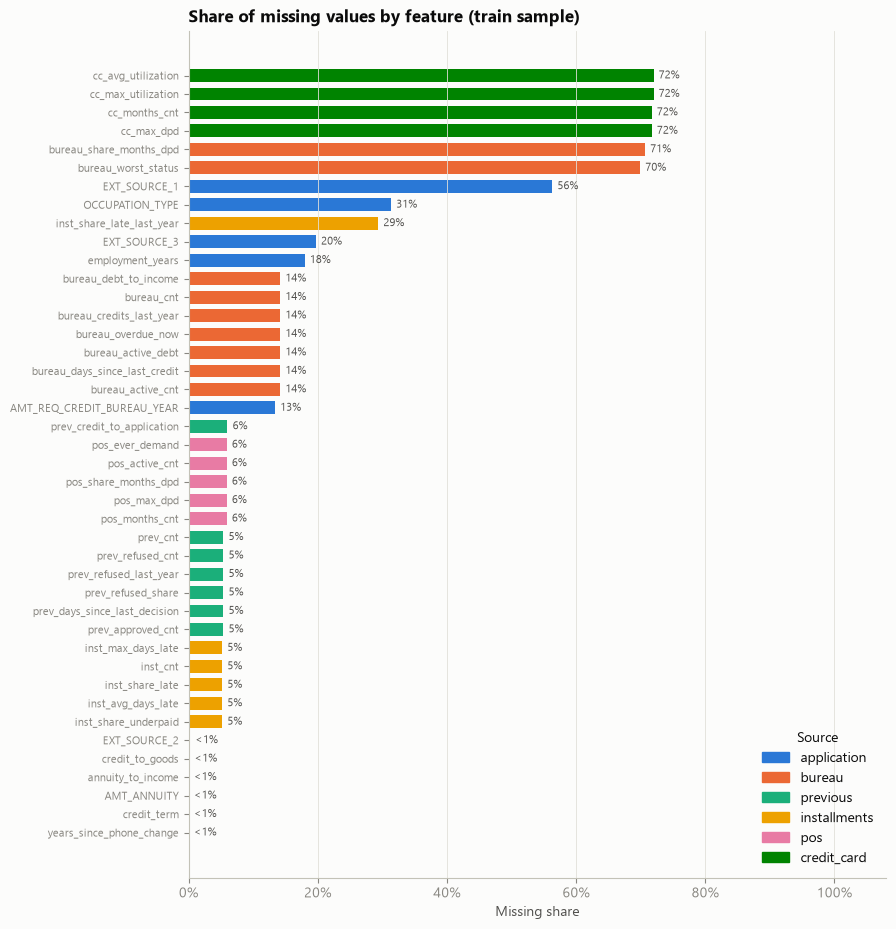

In [12]:
# Missing share per column, coloured by data source
fig, ax = plt.subplots(figsize=(9, 11))
plot_df = missing.sort_values("missing_share")
bars = ax.barh(
    plot_df["column"],
    plot_df["missing_share"],
    color=[SOURCE_COLORS[s] for s in plot_df["source"]],
    height=0.7,
)
# Direct labels: three source colours are low-contrast, so values are written out
for bar, share in zip(bars, plot_df["missing_share"]):
    ax.text(bar.get_width() + 0.008, bar.get_y() + bar.get_height() / 2,
            f"{share:.0%}" if share >= 0.005 else "<1%",
            va="center", fontsize=8, color=INK_SECONDARY)

ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
ax.set_title("Share of missing values by feature (train sample)")
ax.set_xlabel("Missing share")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for s, c in SOURCE_COLORS.items()
           if s in set(plot_df["source"])]
labels = [s for s in SOURCE_COLORS if s in set(plot_df["source"])]
ax.legend(handles, labels, title="Source", loc="lower right")

save_figure(fig, "02_missing_share", FIGURES_DIR)
plt.show()

## 2.2 Risk curves
Bad rate by decile of each key numeric feature. Missing values form their own group
(they are information, decision 17), shown as a separate value in the panel.

In [13]:
def risk_curve(df: pd.DataFrame, feature: str, n_bins: int = 10) -> pd.DataFrame:
    """Bad rate by quantile bin of a numeric feature, plus one row for missing values."""
    present = df[df[feature].notna()]
    # qcut: equal-count bins; duplicates="drop" merges bins when many values are equal (e.g. zeros)
    bins = pd.qcut(present[feature], q=n_bins, duplicates="drop")
    curve = (
        present.groupby(bins, observed=True)
        .agg(x=(feature, "median"), n=("TARGET", "size"), bad_rate=("TARGET", "mean"))
        .reset_index(drop=True)
    )
    missing_part = df[df[feature].isna()]
    if len(missing_part):
        curve.attrs["missing"] = (len(missing_part), missing_part["TARGET"].mean())
    return curve


CURVE_FEATURES = [
    ("EXT_SOURCE_1", "External score 1"),
    ("EXT_SOURCE_2", "External score 2"),
    ("EXT_SOURCE_3", "External score 3"),
    ("age_years", "Age, years"),
    ("employment_years", "Years at current job"),
    ("annuity_to_income", "Annuity / income (H2)"),
    ("credit_to_income", "Credit / income"),
    ("credit_to_goods", "Credit / goods price"),
    ("inst_share_late", "Share of late installments (H1)"),
    ("prev_refused_share", "Share of refused applications"),
    ("bureau_debt_to_income", "Bureau debt / income"),
    ("cc_avg_utilization", "Credit card utilization"),
]

curves = {feat: risk_curve(train, feat) for feat, _ in CURVE_FEATURES}

# Spread between the riskiest and the safest bin: a quick measure of feature strength
strength = pd.DataFrame([
    {
        "feature": feat,
        "n_bins": len(c),
        "min_bad_rate": c["bad_rate"].min(),
        "max_bad_rate": c["bad_rate"].max(),
        "max_to_min": c["bad_rate"].max() / c["bad_rate"].min(),
        "missing_bad_rate": c.attrs.get("missing", (0, np.nan))[1],
    }
    for feat, c in curves.items()
]).sort_values("max_to_min", ascending=False)
strength.round(3)

,feature,n_bins,min_bad_rate,max_bad_rate,max_to_min,missing_bad_rate
0,EXT_SOURCE_1,10,0.027,0.176,6.436,0.085
1,EXT_SOURCE_2,10,0.030,0.184,6.136,0.074
2,EXT_SOURCE_3,10,0.033,0.199,6.073,0.092
11,cc_avg_utilization,7,0.055,0.183,3.334,0.078
4,employment_years,10,0.044,0.115,2.628,0.056
7,credit_to_goods,8,0.051,0.129,2.507,0.057
3,age_years,10,0.048,0.115,2.405,NaN
9,prev_refused_share,4,0.071,0.139,1.953,0.059
8,inst_share_late,6,0.066,0.127,1.913,0.059
10,bureau_debt_to_income,7,0.062,0.096,1.553,0.100


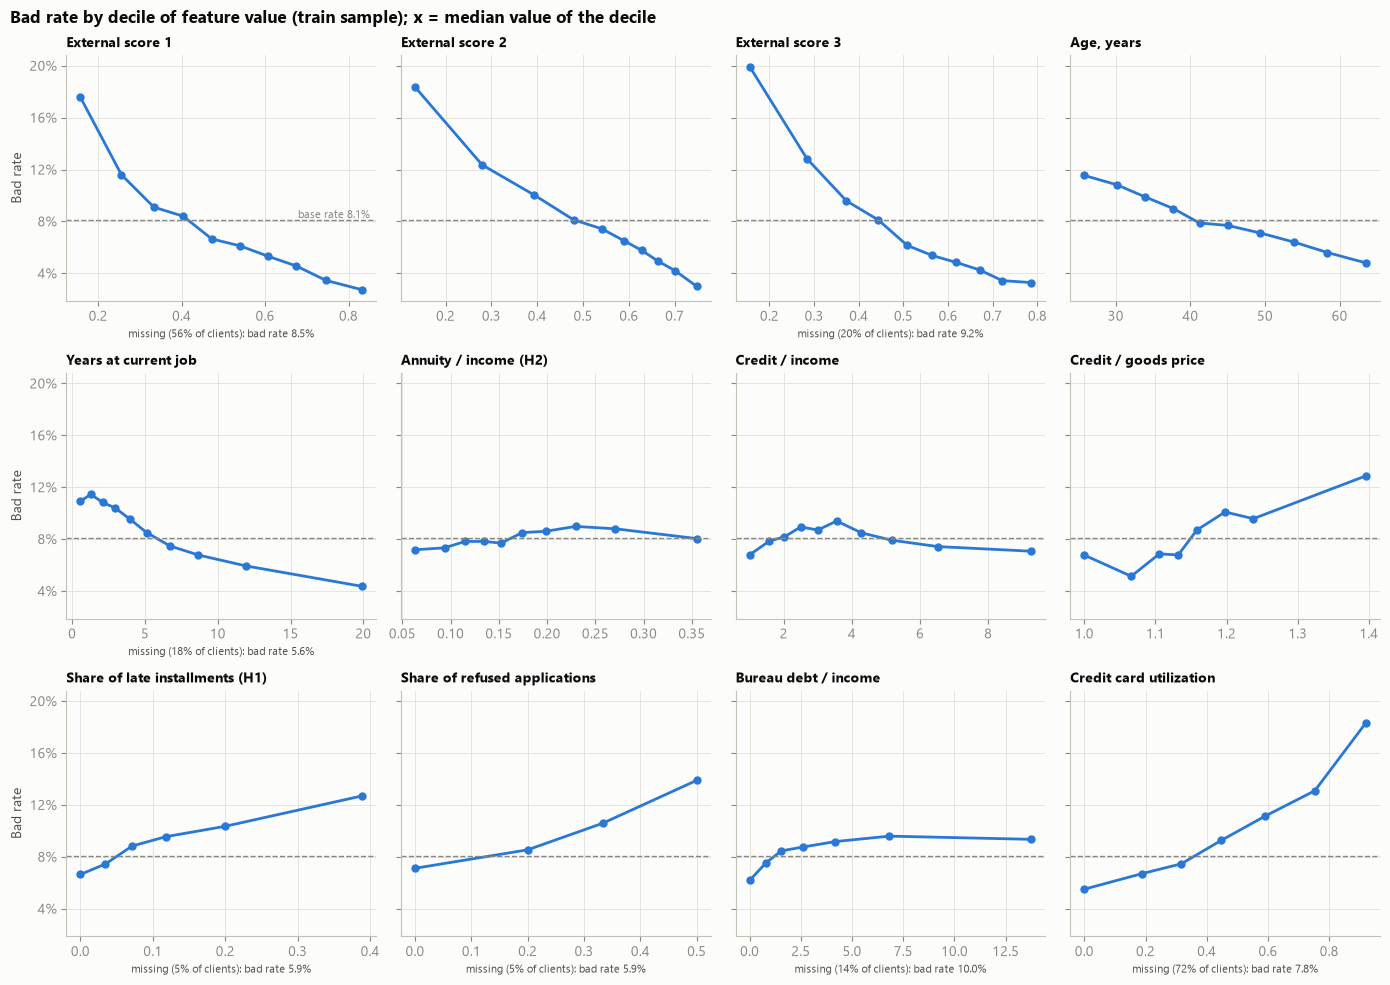

In [14]:
from matplotlib.ticker import MultipleLocator, PercentFormatter

from src.viz import GOOD_COLOR, INK_MUTED

# Small multiples: one panel per feature, shared y axis so slopes are comparable
fig, axes = plt.subplots(3, 4, figsize=(14, 10), sharey=True)

for ax, (feat, title) in zip(axes.flat, CURVE_FEATURES):
    c = curves[feat]
    ax.plot(c["x"], c["bad_rate"], color=GOOD_COLOR, marker="o", markersize=5)
    ax.axhline(base_rate, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.yaxis.set_major_locator(MultipleLocator(0.04))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    # Missing group goes under the axis, so it never collides with the curve;
    # shown only when it is at least 1% of clients
    n_miss, br_miss = c.attrs.get("missing", (0, np.nan))
    if n_miss / len(train) >= 0.01:
        ax.set_xlabel(f"missing ({n_miss / len(train):.0%} of clients): bad rate {br_miss:.1%}",
                      fontsize=8, color=INK_SECONDARY)

for ax in axes[:, 0]:
    ax.set_ylabel("Bad rate")
axes[0, 0].text(0.98, base_rate, f"base rate {base_rate:.1%}", transform=axes[0, 0].get_yaxis_transform(),
                ha="right", va="bottom", fontsize=8, color=INK_MUTED)
fig.suptitle("Bad rate by decile of feature value (train sample); x = median value of the decile",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()

save_figure(fig, "02_risk_curves", FIGURES_DIR)
plt.show()

## 2.3 Correlations between features
Spearman (rank) correlation: robust to outliers and skew, captures any monotonic relation.
Strongly correlated pairs are a problem for logistic regression (unstable coefficients),
so one feature of each pair will be dropped at stage 3.

In [15]:
NUMERIC = [c for c in train.select_dtypes("number").columns if c not in ("SK_ID_CURR", "TARGET")]
corr = train[NUMERIC].corr(method="spearman")

# Upper triangle only: each pair once, no diagonal
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("spearman").reset_index()
pairs.columns = ["feature_1", "feature_2", "spearman"]
high_corr = (
    pairs[pairs["spearman"].abs() >= 0.7]
    .sort_values("spearman", key=abs, ascending=False)
    .reset_index(drop=True)
)
print(f"{len(NUMERIC)} numeric features, {len(high_corr)} pairs with |rho| >= 0.7")
high_corr.round(3)

54 numeric features, 20 pairs with |rho| >= 0.7


,feature_1,feature_2,spearman
0,pos_max_dpd,pos_share_months_dpd,0.994
1,bureau_active_debt,bureau_debt_to_income,0.978
2,prev_refused_cnt,prev_refused_share,0.976
3,bureau_worst_status,bureau_share_months_dpd,0.973
4,inst_avg_days_late,inst_max_days_late,0.971
5,inst_share_late,inst_avg_days_late,0.960
6,has_prev_history,has_inst_history,0.920
7,has_inst_history,has_pos_history,0.908
8,inst_share_late,inst_max_days_late,0.894
9,has_prev_history,has_pos_history,0.880


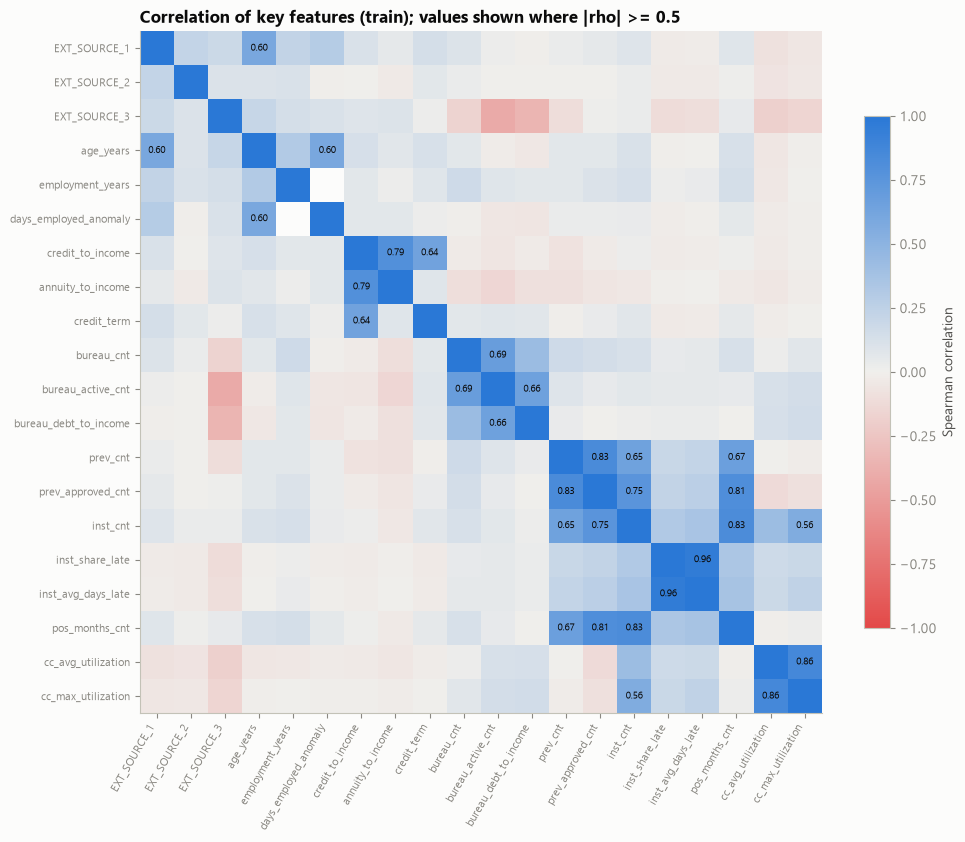

In [16]:
from matplotlib.colors import LinearSegmentedColormap

# Diverging map: red (negative) - neutral gray - blue (positive)
DIVERGING = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])

HEATMAP_FEATURES = [
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "age_years", "employment_years",
    "days_employed_anomaly", "credit_to_income", "annuity_to_income", "credit_term",
    "bureau_cnt", "bureau_active_cnt", "bureau_debt_to_income",
    "prev_cnt", "prev_approved_cnt", "inst_cnt", "inst_share_late", "inst_avg_days_late",
    "pos_months_cnt", "cc_avg_utilization", "cc_max_utilization",
]
sub = corr.loc[HEATMAP_FEATURES, HEATMAP_FEATURES]

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(sub, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(sub)), sub.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(sub)), sub.index, fontsize=8)
ax.grid(False)
# Direct labels only where the relation is notable, to keep the map readable
for i in range(len(sub)):
    for j in range(len(sub)):
        v = sub.iat[i, j]
        if i != j and abs(v) >= 0.5:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman correlation")
ax.set_title("Correlation of key features (train); values shown where |rho| >= 0.5")

save_figure(fig, "02_correlation", FIGURES_DIR)
plt.show()

## 2.4 Hypothesis tests
Large sample: almost any difference is significant, so every test reports an **effect size**
next to the p-value. Five tests, so p-values are adjusted with the Holm correction.

| # | Hypothesis | Population | Test |
|---|---|---|---|
| H1 | At least one late installment in Home Credit raises the bad rate | clients with installment history | z-test for two proportions |
| H2 | Higher debt burden (annuity / income) is related to default | all | Mann-Whitney U |
| H3 | Clients without credit bureau history (thin file) are riskier | all | z-test for two proportions |
| H4 | A refusal in the last year (credit hunger) raises the bad rate | clients with previous applications | z-test for two proportions |
| H5 | Younger clients default more often | all | Mann-Whitney U |

In [17]:
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint, proportions_ztest


def compare_proportions(df: pd.DataFrame, is_risk_group: pd.Series) -> dict:
    """Bad rate in the risk group vs the rest: two-sided z-test, difference with 95% CI, lift."""
    risk = df.loc[is_risk_group, "TARGET"]
    rest = df.loc[~is_risk_group, "TARGET"]
    count = np.array([risk.sum(), rest.sum()])
    nobs = np.array([len(risk), len(rest)])
    _, p_value = proportions_ztest(count, nobs)
    rate_risk, rate_rest = count / nobs
    diff = rate_risk - rate_rest
    se = np.sqrt(rate_risk * (1 - rate_risk) / nobs[0] + rate_rest * (1 - rate_rest) / nobs[1])
    return {
        "test": "z-test (proportions)",
        "n_risk_group": nobs[0],
        "bad_rate_risk_group": rate_risk,
        "bad_rate_rest": rate_rest,
        "effect": f"diff {diff:+.2%} [{diff - 1.96 * se:+.2%}; {diff + 1.96 * se:+.2%}], lift x{rate_risk / rate_rest:.2f}",
        "p_value": p_value,
    }


def compare_distributions(df: pd.DataFrame, feature: str) -> dict:
    """Feature of defaulted vs repaid clients: two-sided Mann-Whitney U, effect = AUC.
    AUC = P(value of a random bad client > value of a random good client);
    0.5 means no relation, distance from 0.5 is the effect size."""
    x = df[[feature, "TARGET"]].dropna()
    bad = x.loc[x["TARGET"] == 1, feature]
    good = x.loc[x["TARGET"] == 0, feature]
    u_stat, p_value = stats.mannwhitneyu(bad, good, alternative="two-sided")
    auc = u_stat / (len(bad) * len(good))
    return {
        "test": "Mann-Whitney U",
        "n_risk_group": np.nan,
        "bad_rate_risk_group": np.nan,
        "bad_rate_rest": np.nan,
        "effect": f"median bad {bad.median():.3f} vs good {good.median():.3f}, AUC {auc:.3f}",
        "p_value": p_value,
    }


inst_clients = train[train["has_inst_history"] == 1]
prev_clients = train[train["has_prev_history"] == 1]

results = pd.DataFrame([
    {"hypothesis": "H1 late installment", **compare_proportions(inst_clients, inst_clients["inst_share_late"] > 0)},
    {"hypothesis": "H2 annuity / income", **compare_distributions(train, "annuity_to_income")},
    {"hypothesis": "H3 no bureau history", **compare_proportions(train, train["has_bureau_history"] == 0)},
    {"hypothesis": "H4 refusal last year", **compare_proportions(prev_clients, prev_clients["prev_refused_last_year"] > 0)},
    {"hypothesis": "H5 age", **compare_distributions(train, "age_years")},
])
results["p_holm"] = multipletests(results["p_value"], method="holm")[1]
results["significant"] = results["p_holm"] < 0.05

with pd.option_context("display.max_colwidth", 90, "display.float_format", "{:.3g}".format):
    display(results)

,hypothesis,test,n_risk_group,bad_rate_risk_group,bad_rate_rest,effect,p_value,p_holm,significant
0,H1 late installment,z-test (proportions),9.32e+04,0.095,0.067,"diff +2.80% [+2.55%; +3.06%], lift x1.42",7.21e-101,2.16e-100,True
1,H2 annuity / income,Mann-Whitney U,NaN,NaN,NaN,"median bad 0.170 vs good 0.162, AUC 0.519",3.65e-14,3.65e-14,True
2,H3 no bureau history,z-test (proportions),2.62e+04,0.1,0.0775,"diff +2.27% [+1.88%; +2.66%], lift x1.29",8.65e-36,1.73e-35,True
3,H4 refusal last year,z-test (proportions),2.84e+04,0.118,0.0749,"diff +4.36% [+3.96%; +4.76%], lift x1.58",9.27e-133,3.71e-132,True
4,H5 age,Mann-Whitney U,NaN,NaN,NaN,"median bad 39.077 vs good 43.428, AUC 0.418",6.71e-243,3.35e-242,True


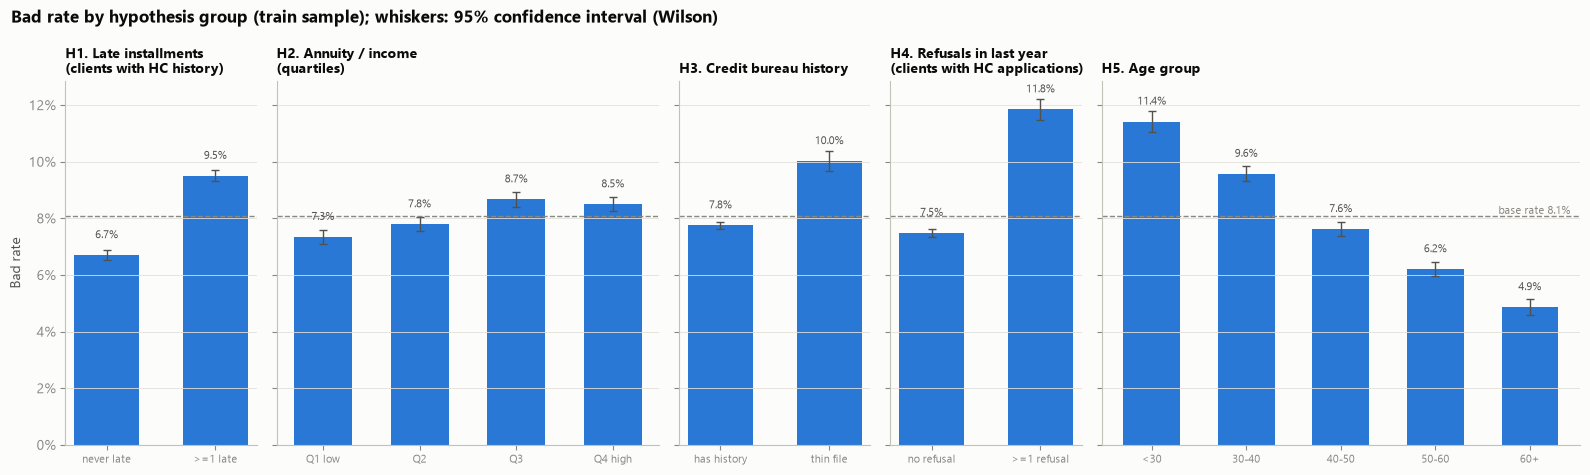

In [18]:
def group_bad_rates(df: pd.DataFrame, groups: pd.Series) -> pd.DataFrame:
    """Bad rate per group with a 95% Wilson confidence interval."""
    t = df.groupby(groups, observed=True)["TARGET"].agg(n="size", bad="sum")
    t["bad_rate"] = t["bad"] / t["n"]
    t["ci_low"], t["ci_high"] = proportion_confint(t["bad"], t["n"], method="wilson")
    return t


H_PANELS = [
    ("H1. Late installments\n(clients with HC history)", inst_clients,
     np.where(inst_clients["inst_share_late"] > 0, ">=1 late", "never late")),
    ("H2. Annuity / income\n(quartiles)", train,
     pd.qcut(train["annuity_to_income"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])),
    ("H3. Credit bureau history", train,
     np.where(train["has_bureau_history"] == 1, "has history", "thin file")),
    ("H4. Refusals in last year\n(clients with HC applications)", prev_clients,
     np.where(prev_clients["prev_refused_last_year"] > 0, ">=1 refusal", "no refusal")),
    ("H5. Age group", train,
     pd.cut(train["age_years"], [0, 30, 40, 50, 60, 100], labels=["<30", "30-40", "40-50", "50-60", "60+"])),
]
GROUP_ORDER = {0: ["never late", ">=1 late"], 2: ["has history", "thin file"], 3: ["no refusal", ">=1 refusal"]}

fig, axes = plt.subplots(1, 5, figsize=(16, 4.8), sharey=True,
                         gridspec_kw={"width_ratios": [2, 4, 2, 2, 5]})
for k, (ax, (title, df, groups)) in enumerate(zip(axes, H_PANELS)):
    t = group_bad_rates(df, pd.Series(groups, index=df.index))
    if k in GROUP_ORDER:
        t = t.loc[GROUP_ORDER[k]]
    x = np.arange(len(t))
    ax.bar(x, t["bad_rate"], color=GOOD_COLOR, width=0.6)
    ax.errorbar(x, t["bad_rate"], yerr=[t["bad_rate"] - t["ci_low"], t["ci_high"] - t["bad_rate"]],
                fmt="none", ecolor=INK_SECONDARY, elinewidth=1, capsize=3)
    for xi, rate in zip(x, t["bad_rate"]):
        ax.text(xi, rate + 0.006, f"{rate:.1%}", ha="center", fontsize=8, color=INK_SECONDARY)
    ax.axhline(base_rate, color=INK_MUTED, linestyle="--", linewidth=1)
    ax.set_xticks(x, t.index, fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))

axes[0].set_ylabel("Bad rate")
axes[-1].text(0.98, base_rate, f"base rate {base_rate:.1%}", transform=axes[-1].get_yaxis_transform(),
              ha="right", va="bottom", fontsize=8, color=INK_MUTED)
fig.suptitle("Bad rate by hypothesis group (train sample); whiskers: 95% confidence interval (Wilson)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()

save_figure(fig, "02_hypotheses", FIGURES_DIR)
plt.show()

## 2.5 Summary of findings (train sample, base bad rate 8.07%)

| # | Finding | Evidence | Effect | Business meaning |
|---|---|---|---|---|
| H4 | A refusal in the last 12 months signals credit hunger | 11.8% vs 7.5% | x1.58, +4.4 pp | Strongest binary signal; a scoring input, not a stop factor: 88% of these clients repay |
| H1 | At least one late installment at Home Credit | 9.5% vs 6.7% | x1.42, +2.8 pp | Own payment history pays off: worth collecting and using |
| H3 | No credit bureau history (thin file) | 10.0% vs 7.8% | x1.29, +2.3 pp | Newcomers need a separate policy (lower limit, extra checks) |
| H5 | Younger clients default more | <30: 11.4%, 60+: 4.9% | AUC 0.418 | Strong, monotonic; age is sensitive: include in the fairness audit |
| H2 | Debt burden (annuity / income) | Q1 7.3%, Q4 8.5% | AUC 0.519 | Significant but negligible **among approved clients**: likely selection bias, the bank already filters high burden |

All five tests are significant after the Holm correction (n = 184 506), so effect sizes, not p-values, rank the findings.

**Other findings**
- External scores are by far the strongest features (x6 between extreme deciles vs x3.3 for the best own feature).
- Missing values carry signal: no bureau history x1.24 risk, no Home Credit history x0.73, pensioners (no employment) x0.69.
- Non-monotonic relations (credit / income, credit / goods price, first years at job) need monotonic WoE binning at stage 3.
- 20 feature pairs with |rho| >= 0.7: one feature of each pair is dropped before logistic regression (by IV).
